# PHÂN TÍCH CÁC YẾU TỐ LIÊN QUAN ĐẾN KHẢ NĂNG SỐNG SÓT CỦA HÀNH KHÁCH TITANIC

**Môn học:** Khoa học dữ liệu trong Kinh tế và Kinh doanh  
**Nguồn dữ liệu:** Kaggle – Titanic: Machine Learning from Disaster  
**Mục tiêu nghiên cứu:** Khám phá mối liên hệ giữa đặc điểm hành khách và khả năng sống sót; kiểm định các giả thuyết thống kê; đồng thời xây dựng mô hình dự báo tham khảo trên dữ liệu Titanic.

> **Lưu ý phương pháp:** Dữ liệu là dữ liệu quan sát lịch sử. Các kết quả phản ánh mối liên hệ thống kê và khả năng dự báo, không đủ cơ sở để khẳng định quan hệ nhân quả.

In [1]:
# ============================================================
# 0. IMPORT THƯ VIỆN VÀ CẤU HÌNH CHUNG
# ============================================================
import os
import warnings
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (8, 5)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

# Tạo thư mục lưu biểu đồ để sử dụng khi biên soạn báo cáo PDF.
os.makedirs("figures", exist_ok=True)

def save_show(name):
    """Lưu biểu đồ ở độ phân giải cao và hiển thị ngay trong Notebook."""
    plt.tight_layout()
    plt.savefig(f"figures/{name}.png", dpi=180, bbox_inches="tight")
    plt.show()

# GIAI ĐOẠN 1: Thu thập và đánh giá dữ liệu ban đầu

## 1.1. Nguồn dữ liệu và cấu trúc

- **Nguồn:** [Kaggle – Titanic: Machine Learning from Disaster](https://www.kaggle.com/competitions/titanic/data).
- `train.csv`: 891 quan sát, 12 thuộc tính, bao gồm biến mục tiêu `Survived`.
- `test.csv`: 418 quan sát, 11 thuộc tính; không có `Survived`, được dùng để minh họa khả năng áp dụng quy trình lên dữ liệu mới.
- `gender_submission.csv`: 418 dòng dự đoán mẫu của Kaggle, không phải nhãn sống sót thực tế nên không dùng để kiểm định giả thuyết.

`PassengerId` là mã định danh. Hai tập train và test được đối chiếu bằng mã này nhưng không gộp thành một tập phân tích vì test không có nhãn `Survived`.

In [2]:
# ============================================================
# 1. ĐỌC DỮ LIỆU
# Ưu tiên các file Kaggle đã có trong thư mục làm việc.
# Nếu chưa có, Colab sẽ yêu cầu tải lên train.csv và test.csv.
# Không âm thầm thay bằng một bản dữ liệu khác để tránh sai lệch nguồn.
# ============================================================
def load_data():
    required_files = ["train.csv", "test.csv"]
    missing_files = [name for name in required_files if not Path(name).exists()]

    if missing_files:
        try:
            from google.colab import files
        except ImportError as exc:
            raise FileNotFoundError(
                "Chưa tìm thấy train.csv và/hoặc test.csv. "
                "Hãy đặt hai file Kaggle này cùng thư mục với Notebook."
            ) from exc

        print("Vui lòng tải lên đủ hai file train.csv và test.csv từ Kaggle.")
        files.upload()

    # Hỗ trợ trường hợp người dùng tải lên file ZIP chứa dữ liệu Titanic.
    if not all(Path(name).exists() for name in required_files):
        zip_candidates = list(Path(".").glob("*.zip"))
        for zip_path in zip_candidates:
            with zipfile.ZipFile(zip_path, "r") as zf:
                members = {Path(name).name: name for name in zf.namelist()}
                for filename in required_files + ["gender_submission.csv"]:
                    if filename in members and not Path(filename).exists():
                        with zf.open(members[filename]) as source, open(filename, "wb") as target:
                            target.write(source.read())

    missing_files = [name for name in required_files if not Path(name).exists()]
    if missing_files:
        raise FileNotFoundError(
            f"Thiếu {missing_files}. Hãy tải đúng các file từ trang Kaggle Titanic."
        )

    train_df = pd.read_csv("train.csv")
    test_df = pd.read_csv("test.csv")
    return train_df, test_df, "Kaggle Titanic CSV"

train, test, source = load_data()

print("Nguồn dữ liệu:", source)
print("Kích thước train:", train.shape)
print("Kích thước test :", test.shape)
display(train.head())

Nguồn dữ liệu: Kaggle Titanic CSV
Kích thước train: (891, 12)
Kích thước test : (418, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 1.2 Từ điển dữ liệu
| Thuộc tính | Ý nghĩa | Kiểu |
|---|---|---|
| PassengerId | Mã hành khách (khóa chính) | Định danh |
| Survived | 0 = tử vong, 1 = sống sót (**biến mục tiêu**) | Nhị phân |
| Pclass | Hạng vé: 1 (cao) – 3 (thấp), đại diện địa vị kinh tế | Thứ bậc |
| Name | Họ tên (chứa danh xưng) | Văn bản |
| Sex | Giới tính | Phân loại |
| Age | Tuổi | Liên tục |
| SibSp | Số anh chị em/vợ chồng đi cùng | Đếm |
| Parch | Số cha mẹ/con cái đi cùng | Đếm |
| Ticket | Số vé | Văn bản |
| Fare | Giá vé | Liên tục |
| Cabin | Số cabin | Văn bản |
| Embarked | Cảng lên tàu: C = Cherbourg, Q = Queenstown, S = Southampton | Phân loại |

In [3]:
# ============================================================
# 1.2. KIỂM TRA CẤU TRÚC VÀ KIỂU DỮ LIỆU
# Lập bảng profile riêng cho train và test để đối chiếu nhất quán.
# ============================================================
def make_data_profile(data, dataset_name):
    profile = pd.DataFrame({
        "Kieu_du_lieu": data.dtypes.astype(str),
        "So_gia_tri_hop_le": data.notna().sum(),
        "So_gia_tri_thieu": data.isna().sum(),
        "Ty_le_thieu_%": (data.isna().mean() * 100).round(2)
    })
    profile.insert(0, "Tap_du_lieu", dataset_name)
    return profile

train.info()
print("\nThống kê mô tả biến số của train:")
display(train.describe().T)
print("\nThống kê mô tả biến phân loại của train:")
display(train.describe(include="object").T)

print("\nBảng kiểm tra cấu trúc train:")
display(make_data_profile(train, "train"))
print("\nBảng kiểm tra cấu trúc test:")
display(make_data_profile(test, "test"))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Thống kê mô tả biến số của train:


,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.000000,257.353842,1.00,223.5000,446.0000,668.5,891.0000
Survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
Pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
Age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
SibSp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
Parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
Fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292



Thống kê mô tả biến phân loại của train:


,count,unique,top,freq
Name,891,891,"Braund, Mr. Owen Harris",1
Sex,891,2,male,577
Ticket,891,681,347082,7
Cabin,204,147,G6,4
Embarked,889,3,S,644



Bảng kiểm tra cấu trúc train:


,Tap_du_lieu,Kieu_du_lieu,So_gia_tri_hop_le,So_gia_tri_thieu,Ty_le_thieu_%
PassengerId,train,int64,891,0,0.00
Survived,train,int64,891,0,0.00
Pclass,train,int64,891,0,0.00
Name,train,object,891,0,0.00
Sex,train,object,891,0,0.00
Age,train,float64,714,177,19.87
SibSp,train,int64,891,0,0.00
Parch,train,int64,891,0,0.00
Ticket,train,object,891,0,0.00
Fare,train,float64,891,0,0.00



Bảng kiểm tra cấu trúc test:


,Tap_du_lieu,Kieu_du_lieu,So_gia_tri_hop_le,So_gia_tri_thieu,Ty_le_thieu_%
PassengerId,test,int64,418,0,0.00
Pclass,test,int64,418,0,0.00
Name,test,object,418,0,0.00
Sex,test,object,418,0,0.00
Age,test,float64,332,86,20.57
SibSp,test,int64,418,0,0.00
Parch,test,int64,418,0,0.00
Ticket,test,object,418,0,0.00
Fare,test,float64,417,1,0.24
Cabin,test,object,91,327,78.23


,so_missing,ty_le_%
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22


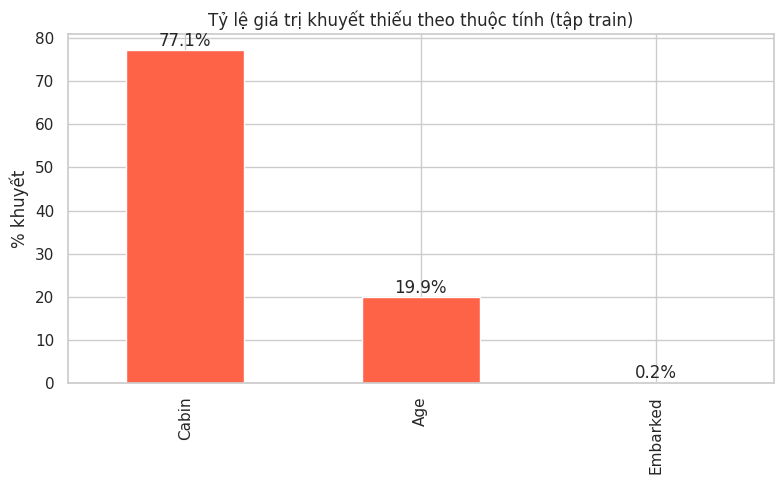

In [4]:
# Tỷ lệ giá trị khuyết thiếu (missing values)
miss = pd.DataFrame({'so_missing': train.isna().sum(),
                     'ty_le_%': (train.isna().mean() * 100).round(2)})
miss = miss[miss.so_missing > 0].sort_values('ty_le_%', ascending=False)
display(miss)

ax = miss['ty_le_%'].plot(kind='bar', color='tomato')
ax.set_title('Tỷ lệ giá trị khuyết thiếu theo thuộc tính (tập train)')
ax.set_ylabel('% khuyết'); ax.set_xlabel('')
for i, v in enumerate(miss['ty_le_%']):
    ax.text(i, v + 1, f'{v:.1f}%', ha='center')
save_show('01_missing')

In [5]:
# ============================================================
# 1.3. KIỂM TRA TÍNH NHẤT QUÁN VÀ KHÓA ĐỊNH DANH
# PassengerId phải duy nhất trong mỗi tập và không giao nhau giữa train/test.
# ============================================================
print("PassengerId duy nhất trong train:", train["PassengerId"].is_unique)
print("PassengerId duy nhất trong test :", test["PassengerId"].is_unique)
print("Dòng trùng hoàn toàn trong train:", train.duplicated().sum())
print("Dòng trùng hoàn toàn trong test :", test.duplicated().sum())

train_ids = set(train["PassengerId"])
test_ids = set(test["PassengerId"])
print("PassengerId giao nhau train/test:", len(train_ids & test_ids))

print("\nCác cột chỉ có trong train:", sorted(set(train.columns) - set(test.columns)))
print("Các cột chỉ có trong test :", sorted(set(test.columns) - set(train.columns)))
print("\nPhân bố biến mục tiêu Survived trong train (%):")
display((train["Survived"].value_counts(normalize=True).sort_index() * 100).round(2)
        .rename(index={0: "Tử vong (0)", 1: "Sống sót (1)"}))

print("\nGiá trị thiếu trong test:")
display(test.isna().sum().loc[lambda s: s > 0].to_frame("So_gia_tri_thieu"))

PassengerId duy nhất trong train: True
PassengerId duy nhất trong test : True
Dòng trùng hoàn toàn trong train: 0
Dòng trùng hoàn toàn trong test : 0
PassengerId giao nhau train/test: 0

Các cột chỉ có trong train: ['Survived']
Các cột chỉ có trong test : []

Phân bố biến mục tiêu Survived trong train (%):


,proportion
Survived,
Tử vong (0),61.62
Sống sót (1),38.38



Giá trị thiếu trong test:


,So_gia_tri_thieu
Age,86
Fare,1
Cabin,327


### Nhận xét và đánh giá giai đoạn 1

Bộ dữ liệu được lựa chọn là **Titanic: Machine Learning from Disaster** trên Kaggle. Tập `train.csv` gồm **891 hành khách và 12 thuộc tính**, trong đó `Survived` là biến mục tiêu; tập `test.csv` gồm **418 hành khách và 11 thuộc tính**, không có nhãn sống sót. Vì vậy, nhóm sử dụng train cho phân tích mô tả, kiểm định giả thuyết và đánh giá mô hình; test chỉ được dùng để minh họa việc áp dụng mô hình lên dữ liệu chưa có nhãn.

Trong tập train, có **342 hành khách sống sót (38,38%)** và **549 hành khách không sống sót (61,62%)**. Tỷ lệ này cho thấy hai lớp không cân bằng hoàn toàn, do đó khi đánh giá mô hình không nên chỉ dựa vào Accuracy mà cần xem thêm Precision, Recall, F1-score và ROC-AUC.

Kiểm tra dữ liệu cho thấy ba thuộc tính thiếu đáng chú ý trong train là `Cabin` (**687 giá trị; 77,10%**), `Age` (**177; 19,87%**) và `Embarked` (**2; 0,22%**). Các bảng profile ở trên đồng thời cung cấp kiểu dữ liệu và tỷ lệ thiếu của cả train lẫn test, giúp nhóm xác định cách xử lý phù hợp cho từng trường.

`PassengerId` được dùng làm mã định danh, không phải biến giải thích. Nhóm kiểm tra tính duy nhất và mức độ giao nhau giữa hai tập; không gộp train với test vì test không có `Survived`. Không phát hiện dòng trùng hoàn toàn trong train theo kết quả kiểm tra ban đầu.

**Kết luận giai đoạn 1:** dữ liệu có cấu trúc phù hợp cho bài toán phân loại nhị phân, nhưng cần xử lý dữ liệu thiếu và xem xét phân phối lệch của một số biến trước khi phân tích và xây dựng mô hình. Các kết quả kiểm định có giám sát chỉ được tính trên train.

# GIAI ĐOẠN 2: Tiền xử lý và làm sạch dữ liệu

## 2.1 Kiểm tra định dạng và dữ liệu trùng lặp

In [6]:
df = train.copy()   # làm việc trên bản sao, giữ nguyên dữ liệu gốc

# Kiểm tra định dạng: giá trị phân loại, khoảng trắng, giá trị âm/vô lý
df['Name'] = df['Name'].str.strip()
print('Giá trị Sex     :', df['Sex'].unique())
print('Giá trị Embarked:', df['Embarked'].dropna().unique())
print('Giá trị Pclass  :', sorted(df['Pclass'].unique()))
print('Age < 0 hoặc > 100:', ((df.Age < 0) | (df.Age > 100)).sum())
print('Fare < 0:', (df.Fare < 0).sum(), '| Fare = 0:', (df.Fare == 0).sum())
print('Age có phần thập phân (trẻ sơ sinh, hợp lệ):', (df.Age.dropna() % 1 != 0).sum())

# Trùng lặp: bỏ PassengerId rồi kiểm tra lại
print('Dòng trùng (bỏ PassengerId):', df.drop(columns='PassengerId').duplicated().sum())
print('Số vé dùng chung bởi nhiều người (gia đình/nhóm đi cùng, hợp lệ):', df.Ticket.duplicated().sum())

Giá trị Sex     : ['male' 'female']
Giá trị Embarked: ['S' 'C' 'Q']
Giá trị Pclass  : [np.int64(1), np.int64(2), np.int64(3)]
Age < 0 hoặc > 100: 0
Fare < 0: 0 | Fare = 0: 15
Age có phần thập phân (trẻ sơ sinh, hợp lệ): 25
Dòng trùng (bỏ PassengerId): 0
Số vé dùng chung bởi nhiều người (gia đình/nhóm đi cùng, hợp lệ): 210


## 2.2 Phát hiện ngoại lệ (outliers) bằng phương pháp IQR

,Thuoc_tinh,Can_duoi,Can_tren,So_ngoai_le,Ty_le_%,Skewness
0,Age,-6.69,64.81,11,1.5,0.39
1,Fare,-26.72,65.63,116,13.0,4.79
2,SibSp,-1.50,2.50,46,5.2,3.70
3,Parch,0.00,0.00,213,23.9,2.75


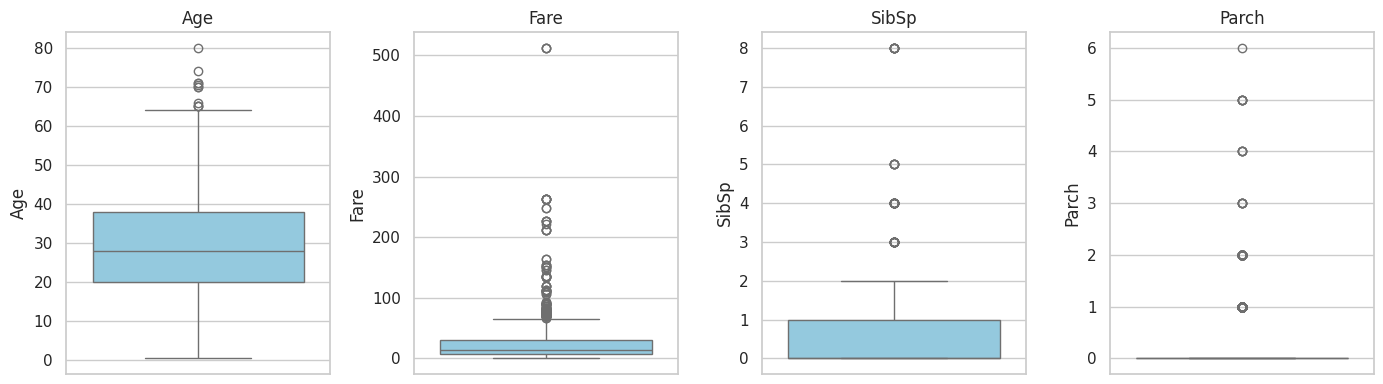

Top 5 giá vé cao nhất:


,Name,Pclass,Fare,Survived
258,"Ward, Miss. Anna",1,512.3292,1
679,"Cardeza, Mr. Thomas Drake Martinez",1,512.3292,1
737,"Lesurer, Mr. Gustave J",1,512.3292,1
27,"Fortune, Mr. Charles Alexander",1,263.0000,0
88,"Fortune, Miss. Mabel Helen",1,263.0000,1


In [7]:
# ============================================================
# 2.2. PHÁT HIỆN NGOẠI LỆ BẰNG IQR
# IQR = Q3 - Q1; ngưỡng ngoại lệ: nhỏ hơn Q1 - 1.5*IQR
# hoặc lớn hơn Q3 + 1.5*IQR. Đây là cờ rà soát, không tự động là lỗi.
# ============================================================
def iqr_bounds(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

rows = []
for column in ["Age", "Fare", "SibSp", "Parch"]:
    values = df[column].dropna()
    lower, upper = iqr_bounds(values)
    n_outliers = ((values < lower) | (values > upper)).sum()
    rows.append([
        column, round(lower, 2), round(upper, 2), int(n_outliers),
        round(n_outliers / len(values) * 100, 1), round(values.skew(), 2)
    ])

outlier_summary = pd.DataFrame(
    rows,
    columns=["Thuoc_tinh", "Can_duoi", "Can_tren", "So_ngoai_le", "Ty_le_%", "Skewness"]
)
display(outlier_summary)

# Boxplot dùng để quan sát hình dạng phân phối và các điểm nằm ngoài ngưỡng IQR.
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for axis, column in zip(axes, ["Age", "Fare", "SibSp", "Parch"]):
    sns.boxplot(y=df[column], ax=axis, color="skyblue")
    axis.set_title(column)
save_show("02_outliers_boxplot")

print("Top 5 giá vé cao nhất:")
display(df.nlargest(5, "Fare")[["Name", "Pclass", "Fare", "Survived"]])

**Giải trình phát hiện và xử lý ngoại lệ:** Phương pháp IQR được sử dụng để nhận diện các quan sát nằm xa phần phân phối trung tâm. Tuy nhiên, IQR chỉ là công cụ sàng lọc thống kê; một giá trị bị đánh dấu không đồng nghĩa với dữ liệu sai. Nhóm vì vậy không xóa hoặc winsorize tự động các quan sát này.

Đặc biệt, `Parch` có Q1 = 0 và Q3 = 0 nên IQR bằng 0. Theo quy tắc IQR, mọi giá trị dương đều bị đánh dấu là ngoại lệ. Đây là hệ quả của phân phối tập trung nhiều ở giá trị 0, không phải bằng chứng rằng tất cả các trường hợp có cha mẹ/con cái đi cùng đều sai. Tương tự, các giá trị `SibSp` lớn có thể phản ánh gia đình đông người.

Đối với `Fare`, giá trị cao nhất cần được đối chiếu với hạng vé và thông tin hành khách. Nhóm giữ lại các giá trị hợp lệ và tạo thêm `LogFare = log1p(Fare)` nhằm giảm độ lệch phải, giúp biểu diễn phân phối dễ đọc hơn. Những trường hợp `Fare = 0` được rà soát riêng ở ô tiếp theo; không tự động thay thế nếu chưa có bằng chứng đó là lỗi ghi nhận.

In [8]:
# ============================================================
# 2.2.1. RÀ SOÁT CÁC QUAN SÁT CÓ FARE = 0
# Mục tiêu là xem xét bối cảnh từng dòng, không mặc định đây là lỗi.
# ============================================================
fare_zero = df.loc[df["Fare"].eq(0),
                   ["PassengerId", "Name", "Pclass", "Ticket", "Fare", "Survived"]]
print("Số hành khách có Fare = 0:", len(fare_zero))
display(fare_zero)

print("\nPhân bố hạng vé của nhóm Fare = 0:")
display(fare_zero["Pclass"].value_counts(dropna=False).sort_index())
print("\nTỷ lệ sống sót của nhóm Fare = 0 (chỉ mô tả, cỡ mẫu nhỏ):")
if len(fare_zero) > 0:
    print(f"{fare_zero['Survived'].mean():.1%}")

Số hành khách có Fare = 0: 15


,PassengerId,Name,Pclass,Ticket,Fare,Survived
179,180,"Leonard, Mr. Lionel",3,LINE,0.0,0
263,264,"Harrison, Mr. William",1,112059,0.0,0
271,272,"Tornquist, Mr. William Henry",3,LINE,0.0,1
277,278,"Parkes, Mr. Francis ""Frank""",2,239853,0.0,0
302,303,"Johnson, Mr. William Cahoone Jr",3,LINE,0.0,0
413,414,"Cunningham, Mr. Alfred Fleming",2,239853,0.0,0
466,467,"Campbell, Mr. William",2,239853,0.0,0
481,482,"Frost, Mr. Anthony Wood ""Archie""",2,239854,0.0,0
597,598,"Johnson, Mr. Alfred",3,LINE,0.0,0
633,634,"Parr, Mr. William Henry Marsh",1,112052,0.0,0



Phân bố hạng vé của nhóm Fare = 0:


,count
Pclass,
1,5
2,6
3,4



Tỷ lệ sống sót của nhóm Fare = 0 (chỉ mô tả, cỡ mẫu nhỏ):
6.7%


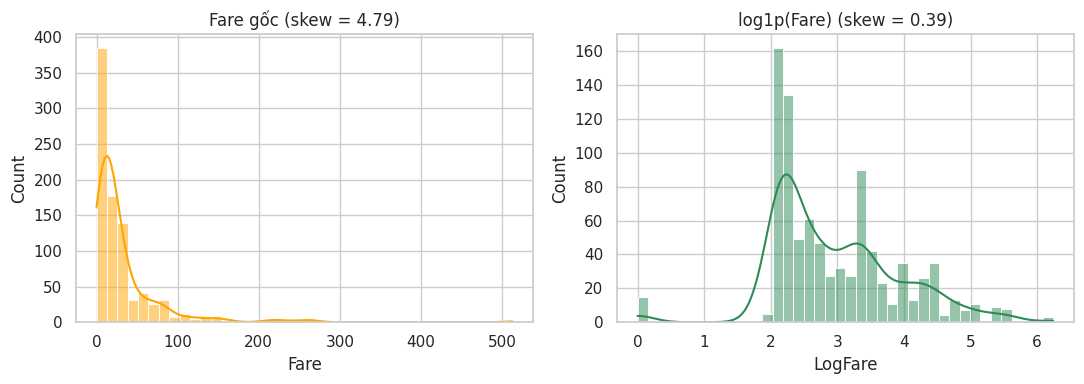

Skewness trước biến đổi: 4.787
Skewness sau biến đổi  : 0.395


In [9]:
# ============================================================
# 2.2.2. BIẾN ĐỔI LOGARITHM CHO FARE
# log1p(x) = log(1+x), xử lý được cả trường hợp Fare = 0.
# ============================================================
df["LogFare"] = np.log1p(df["Fare"].clip(lower=0))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df["Fare"], bins=40, kde=True, ax=axes[0], color="orange")
axes[0].set_title(f"Fare gốc (skew = {df['Fare'].skew():.2f})")
sns.histplot(df["LogFare"], bins=40, kde=True, ax=axes[1], color="seagreen")
axes[1].set_title(f"log1p(Fare) (skew = {df['LogFare'].skew():.2f})")
save_show("03_fare_log")

print("Skewness trước biến đổi:", round(df["Fare"].skew(), 3))
print("Skewness sau biến đổi  :", round(df["LogFare"].skew(), 3))

## 2.3. Xử lý giá trị khuyết thiếu

- **Age:** điền Median theo nhóm `Title × Pclass`, sau đó dự phòng bằng Median theo `Title` và Median toàn bộ. Cách làm theo nhóm phản ánh sự khác biệt về độ tuổi giữa các danh xưng và hạng vé; Median ít nhạy với các giá trị cực đoan hơn Mean. Đồng thời tạo `Age_missing` để giữ thông tin về việc tuổi ban đầu bị khuyết.
- **Embarked:** điền Mode vì chỉ thiếu 2/891 quan sát (0,22%) và đây là biến phân loại.
- **Cabin:** không tự tạo số cabin giả. Tạo `Has_Cabin` (có/không có thông tin cabin) và `Deck` (ký tự đầu của Cabin, nhóm thiếu thành `U`). Biến Cabin gốc được giữ trong dữ liệu ban đầu để truy vết.

Lưu ý: bước điền Age này phục vụ phân tích khám phá và trực quan hóa. Ở phần mô hình dự báo, việc điền khuyết được đặt bên trong Pipeline để mỗi fold chỉ học tham số từ phần huấn luyện của fold đó, hạn chế data leakage. Trong Pipeline, Age được điền bằng Median chung của phần training (đơn giản hơn Median theo Title × Pclass dùng ở phần khám phá), nên kết quả mô hình có thể khác nhẹ so với dữ liệu đã điền ở phần phân tích.

In [10]:
# Trích danh xưng (Title) từ Name, gộp các danh xưng hiếm
df['Title'] = df['Name'].str.extract(r',\s*([^\.]+)\.', expand=False).str.strip()
title_map = {'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs', 'Lady': 'Rare', 'the Countess': 'Rare',
             'Capt': 'Rare', 'Col': 'Rare', 'Don': 'Rare', 'Dr': 'Rare', 'Major': 'Rare',
             'Rev': 'Rare', 'Sir': 'Rare', 'Jonkheer': 'Rare', 'Dona': 'Rare'}
df['Title'] = df['Title'].replace(title_map)
display(df['Title'].value_counts())

# Minh chứng chọn Median: so sánh Mean và Median của Age theo nhóm
age_stat = df.groupby('Title')['Age'].agg(['count', 'mean', 'median']).round(1)
display(age_stat)
print('Skewness của Age:', round(df['Age'].skew(), 2))

,count
Title,
Mr,517
Miss,185
Mrs,126
Master,40
Rare,23


,count,mean,median
Title,,,
Master,36,4.6,3.5
Miss,149,21.8,21.0
Mr,398,32.4,30.0
Mrs,109,35.8,35.0
Rare,22,45.5,48.5


Skewness của Age: 0.39


In [11]:
# ============================================================
# 2.3. XỬ LÝ GIÁ TRỊ KHUYẾT THIẾU
# Age: median theo Title x Pclass -> median theo Title -> median toàn bộ.
# Embarked: mode do chỉ thiếu rất ít quan sát và là biến phân loại.
# Cabin: giữ thông tin có/không có cabin và nhóm boong tàu, không bịa số cabin.
# ============================================================
df["Age_missing"] = df["Age"].isna().astype(int)

# Điền tuổi theo nhóm đồng nhất hơn về danh xưng và hạng vé.
df["Age"] = df["Age"].fillna(
    df.groupby(["Title", "Pclass"])["Age"].transform("median")
)
# Dự phòng nếu một nhóm không có giá trị tuổi để tính median.
df["Age"] = df["Age"].fillna(
    df.groupby("Title")["Age"].transform("median")
)
df["Age"] = df["Age"].fillna(df["Age"].median())

# Embarked chỉ thiếu 2 quan sát trong train; dùng mode của tập train.
mode_embarked = df["Embarked"].mode()[0]
df["Embarked"] = df["Embarked"].fillna(mode_embarked)

# Cabin thiếu nhiều; tạo đặc trưng có thông tin cabin và ký tự boong.
df["Has_Cabin"] = df["Cabin"].notna().astype(int)
df["Deck"] = df["Cabin"].str[0].fillna("U")

print("Mode của Embarked:", mode_embarked)
print("Tổng missing còn lại (không tính Cabin gốc):",
      df.drop(columns="Cabin").isna().sum().sum())

Mode của Embarked: S
Tổng missing còn lại (không tính Cabin gốc): 0


## 2.4 Tạo đặc trưng mới (Feature Engineering)

In [12]:
# ============================================================
# 2.4. FEATURE ENGINEERING
# Tạo biến mới có ý nghĩa diễn giải từ các trường dữ liệu gốc.
# ============================================================
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)

# Phân nhóm tuổi để so sánh tỷ lệ sống sót giữa các giai đoạn tuổi.
df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[0, 12, 18, 35, 60, 100],
    labels=["Trẻ em (0-12)", "Thiếu niên (13-18)",
            "Thanh niên (19-35)", "Trung niên (36-60)", "Cao tuổi (60+)"]
)

# FarePerPerson là biến khám phá; không đưa vào mô hình chính để tránh
# bổ sung biến có thể chồng lấn thông tin với Fare và FamilySize.
df["FarePerPerson"] = df["Fare"] / df["FamilySize"]

display(df[["Age", "Title", "FamilySize", "IsAlone", "AgeGroup",
            "Has_Cabin", "Deck", "LogFare", "FarePerPerson"]].head())

,Age,Title,FamilySize,IsAlone,AgeGroup,Has_Cabin,Deck,LogFare,FarePerPerson
0,22.0,Mr,2,0,Thanh niên (19-35),0,U,2.110213,3.62500
1,38.0,Mrs,2,0,Trung niên (36-60),1,C,4.280593,35.64165
2,26.0,Miss,1,1,Thanh niên (19-35),0,U,2.188856,7.92500
3,35.0,Mrs,2,0,Thanh niên (19-35),1,C,3.990834,26.55000
4,35.0,Mr,1,1,Thanh niên (19-35),0,U,2.202765,8.05000


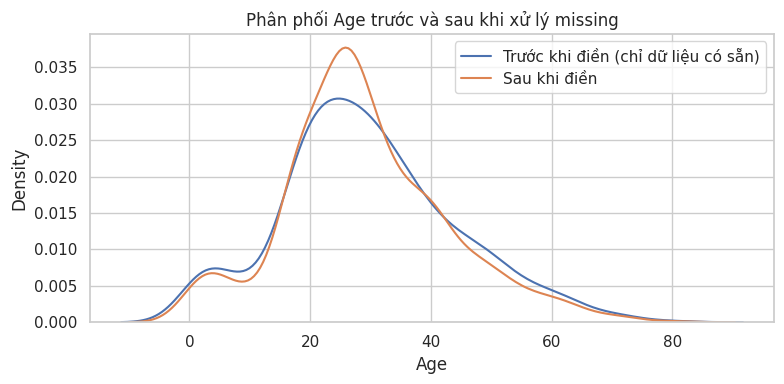

Mean/Median trước: 29.7 / 28.0 | sau: 29.14 / 26.0


In [13]:
# Kiểm chứng: phân phối Age trước và sau khi điền
fig, ax = plt.subplots(figsize=(8, 4))
sns.kdeplot(train['Age'].dropna(), label='Trước khi điền (chỉ dữ liệu có sẵn)', ax=ax)
sns.kdeplot(df['Age'], label='Sau khi điền', ax=ax)
ax.set_title('Phân phối Age trước và sau khi xử lý missing'); ax.legend()
save_show('04_age_before_after')
print('Mean/Median trước:', round(train.Age.mean(), 2), '/', train.Age.median(),
      '| sau:', round(df.Age.mean(), 2), '/', df.Age.median())

## 2.5. Mã hóa và chuẩn hóa dữ liệu

- **One-Hot Encoding:** dùng cho `Sex`, `Embarked`, `Title` và `Pclass`. Mặc dù `Pclass` có thứ bậc, nhóm xử lý nó như biến phân loại trong mô hình chính để không áp đặt giả định rằng khoảng cách giữa hạng 1–2 bằng khoảng cách giữa hạng 2–3.
- **StandardScaler:** áp dụng cho các biến số trong Pipeline. Chuẩn hóa giúp Logistic Regression tối ưu ổn định hơn khi các biến có đơn vị và độ lớn khác nhau. Random Forest không phụ thuộc mạnh vào thang đo, nhưng dùng chung quy trình tiền xử lý để so sánh nhất quán.
- **Imputation:** Median cho biến số và giá trị xuất hiện nhiều nhất cho biến phân loại. Median phù hợp hơn Mean khi phân phối có lệch hoặc ngoại lệ.
- **Chống Data Leakage:** imputer, encoder và scaler được đặt bên trong `Pipeline`; chúng chỉ được fit trên phần training của từng fold, không học thông tin từ fold validation.

Các biến `Deck`, `AgeGroup`, `IsAlone` và `FarePerPerson` được tạo để hỗ trợ khám phá và diễn giải. Mô hình chính chỉ dùng một tập biến được chọn trước, tránh đưa đồng thời nhiều biến gần như trùng lặp thông tin hoặc làm tăng số chiều không cần thiết.

In [14]:
# ============================================================
# 2.6. TẠO MA TRẬN ĐẶC TRƯNG CHO MÔ HÌNH
# Chỉ tạo biến theo từng dòng tại đây. Các bước học tham số như
# imputation, encoding và scaling được thực hiện trong Pipeline.
# ============================================================
def build_model_features(data):
    out = data.copy()

    # Trích danh xưng và gộp các danh xưng hiếm để giảm số nhóm nhỏ.
    out["Title"] = out["Name"].str.extract(
        r",\s*([^\.]+)\.", expand=False
    ).str.strip()
    title_map_model = {
        "Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs",
        "Lady": "Rare", "the Countess": "Rare", "Capt": "Rare",
        "Col": "Rare", "Don": "Rare", "Dr": "Rare", "Major": "Rare",
        "Rev": "Rare", "Sir": "Rare", "Jonkheer": "Rare", "Dona": "Rare"
    }
    out["Title"] = out["Title"].replace(title_map_model)

    # Tạo các đặc trưng dẫn xuất có thể tính độc lập cho từng hành khách.
    out["FamilySize"] = out["SibSp"] + out["Parch"] + 1
    out["Has_Cabin"] = out["Cabin"].notna().astype(int)
    out["Age_missing"] = out["Age"].isna().astype(int)
    out["LogFare"] = np.log1p(out["Fare"].clip(lower=0))

    features = [
        "Age", "LogFare", "FamilySize", "Has_Cabin", "Age_missing",
        "Sex", "Embarked", "Title", "Pclass"
    ]
    return out[features]

X_model = build_model_features(train)
y = train["Survived"].copy()

print("Kích thước ma trận đặc trưng:", X_model.shape)
display(X_model.head())

Kích thước ma trận đặc trưng: (891, 9)


,Age,LogFare,FamilySize,Has_Cabin,Age_missing,Sex,Embarked,Title,Pclass
0,22.0,2.110213,2,0,0,male,S,Mr,3
1,38.0,4.280593,2,1,0,female,C,Mrs,1
2,26.0,2.188856,1,0,0,female,S,Miss,3
3,35.0,3.990834,2,1,0,female,S,Mrs,1
4,35.0,2.202765,1,0,0,male,S,Mr,3


### Nhận xét và đánh giá giai đoạn 2

Quá trình làm sạch được thực hiện trên bản sao `df` để bảo toàn dữ liệu gốc `train`. Nhóm đã rà soát định dạng các biến, giá trị âm hoặc nằm ngoài phạm vi hợp lý, dòng trùng lặp và các trường hợp có giá trị cực đoan. Mã vé xuất hiện ở nhiều hành khách không được xem là trùng lặp tự động vì có thể là vé dùng chung của gia đình hoặc nhóm.

Với dữ liệu thiếu, `Age` được điền bằng Median theo nhóm `Title × Pclass`, sau đó dùng các mức Median dự phòng nếu nhóm không có đủ dữ liệu. Cách làm này khai thác sự khác biệt về độ tuổi giữa các danh xưng và hạng vé, đồng thời ít bị kéo lệch bởi các giá trị cực đoan hơn Mean. Biến `Age_missing` được tạo để lưu lại thông tin ban đầu về việc thiếu tuổi. `Embarked` được điền bằng Mode vì chỉ thiếu 2 quan sát. Do `Cabin` thiếu tới 77,10%, nhóm không tự suy đoán số cabin mà tạo `Has_Cabin` và `Deck` để giữ lại phần thông tin còn quan sát được.

Phương pháp IQR cho thấy một số giá trị nằm ngoài khoảng phân vị, nhưng nhóm không loại bỏ máy móc vì các giá trị này có thể phản ánh đặc điểm thật của hành khách. Trường hợp `Parch` cần giải thích riêng do Q1 và Q3 đều bằng 0 khiến IQR bằng 0; vì vậy các giá trị dương bị đánh dấu theo quy tắc toán học chứ không nhất thiết là sai. `Fare` được biến đổi bằng `log1p` để giảm độ lệch phải, không phải để xóa các quan sát có giá trị cao.

Nhóm bổ sung các đặc trưng như `Title`, `FamilySize`, `IsAlone`, `AgeGroup`, `Has_Cabin` và `FarePerPerson` nhằm hỗ trợ phân tích. Không phải tất cả đặc trưng đều được đưa vào mô hình; việc lựa chọn được giới hạn để tránh thông tin trùng lặp và tăng độ phức tạp không cần thiết.

**Kết luận giai đoạn 2:** dữ liệu đã được xử lý theo nguyên tắc giữ lại quan sát hợp lệ, giải trình rõ lựa chọn kỹ thuật và tách biệt tiền xử lý phục vụ EDA với tiền xử lý trong Pipeline mô hình. Điều này giúp giảm nguy cơ Data Leakage khi đánh giá bằng kiểm định chéo.

# GIAI ĐOẠN 3: Phân tích và trực quan hóa

## 3.1. Hệ giả thuyết nghiên cứu và phương pháp kiểm định

Nhóm xây dựng các giả thuyết nhằm kiểm tra mối liên hệ giữa đặc điểm hành khách và tình trạng sống sót:

- **H1:** Tỷ lệ sống sót khác nhau giữa nam và nữ; dự kiến nữ có tỷ lệ cao hơn.
- **H2:** Tỷ lệ sống sót khác nhau theo hạng vé; dự kiến hành khách hạng 1 có tỷ lệ cao hơn hạng 2 và hạng 3.
- **H3:** Tỷ lệ sống sót khác nhau giữa các nhóm tuổi; dự kiến trẻ em có tỷ lệ cao hơn.
- **H4:** Tỷ lệ sống sót khác nhau theo quy mô gia đình; dự kiến nhóm gia đình 2–4 người có tỷ lệ cao hơn nhóm đi một mình và nhóm gia đình đông.
- **H5:** Phân phối giá vé khác nhau giữa nhóm sống sót và không sống sót; dự kiến nhóm sống sót có giá vé cao hơn.
- **H6:** Tình trạng sống sót có liên hệ với cảng lên tàu; cần xem xét khả năng khác biệt này liên quan đến cơ cấu hạng vé.

**Phương pháp:** Chi-square được sử dụng cho các biến phân loại; Mann–Whitney U được sử dụng để so sánh phân phối biến liên tục giữa hai nhóm sống sót và tử vong, không yêu cầu giả định phân phối chuẩn. Cramér's V được báo cáo để đánh giá cỡ ảnh hưởng của kiểm định Chi-square. Mức ý nghĩa thống kê được chọn là \(\alpha = 0,05\).

Các kiểm định là phân tích quan sát trên cùng một bộ dữ liệu, do đó p-value không chứng minh quan hệ nhân quả. Vì nhóm thực hiện nhiều kiểm định, các kết quả có p-value gần 0,05 cần được diễn giải thận trọng.

In [15]:
# ============================================================
# 3.1. HÀM KIỂM ĐỊNH CHI-SQUARE VÀ CỠ ẢNH HƯỞNG
# Báo cáo Cramér's V và số ô có tần suất kỳ vọng < 5 để kiểm tra
# mức độ đáp ứng điều kiện xấp xỉ của kiểm định Chi-square.
# ============================================================
def chi2_test(col, data=None):
    data = df if data is None else data
    contingency_table = pd.crosstab(data[col], data["Survived"])
    chi2, p_value, dof, expected = stats.chi2_contingency(contingency_table)

    n = contingency_table.to_numpy().sum()
    cramers_v = np.sqrt(
        chi2 / (n * (min(contingency_table.shape) - 1))
    )
    low_expected = int((expected < 5).sum())
    total_cells = int(expected.size)

    print(
        f"[{col}] Chi-square = {chi2:.2f}, df = {dof}, "
        f"p-value = {p_value:.3e}, Cramér's V = {cramers_v:.3f}"
    )
    print(
        f"Ô có tần suất kỳ vọng < 5: {low_expected}/{total_cells} "
        f"({low_expected / total_cells:.1%})"
    )
    if low_expected > 0:
        print("Lưu ý: cần thận trọng với xấp xỉ Chi-square; cân nhắc gộp nhóm hợp lý.")
    print(
        "Kết luận:",
        "Có bằng chứng về mối liên hệ thống kê (p < 0,05)."
        if p_value < 0.05
        else "Chưa đủ bằng chứng về mối liên hệ thống kê (p ≥ 0,05)."
    )

    return {
        "chi2": chi2, "p_value": p_value, "dof": dof,
        "cramers_v": cramers_v, "expected": expected,
        "table": contingency_table
    }


def rate_bar(col, order=None, title="", fname=""):
    """Vẽ tỷ lệ sống sót theo nhóm, kèm cỡ mẫu và tỷ lệ chung."""
    grouped = df.groupby(col, observed=True)["Survived"].agg(["mean", "count"])
    if order is not None:
        grouped = grouped.reindex(order).dropna(subset=["mean"])

    fig, ax = plt.subplots(figsize=(8, 5))
    bars = ax.bar(
        grouped.index.astype(str), grouped["mean"] * 100,
        color=sns.color_palette("deep", len(grouped))
    )
    for bar, (mean_value, sample_size) in zip(
        bars, grouped[["mean", "count"]].to_numpy()
    ):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            mean_value * 100 + 1,
            f"{mean_value * 100:.1f}%\n(n={int(sample_size)})",
            ha="center"
        )

    overall_rate = df["Survived"].mean() * 100
    ax.axhline(
        overall_rate, linestyle="--", color="gray",
        label=f"Tỷ lệ sống sót chung ({overall_rate:.1f}%)"
    )
    ax.set_ylabel("Tỷ lệ sống sót (%)")
    ax.set_ylim(0, max(grouped["mean"] * 100) + 15)
    ax.set_title(title)
    ax.legend()
    save_show(fname)
    return grouped

### H1 – Giới tính

[Sex] Chi-square = 260.72, df = 1, p-value = 1.197e-58, Cramér's V = 0.541
Ô có tần suất kỳ vọng < 5: 0/4 (0.0%)
Kết luận: Có bằng chứng về mối liên hệ thống kê (p < 0,05).


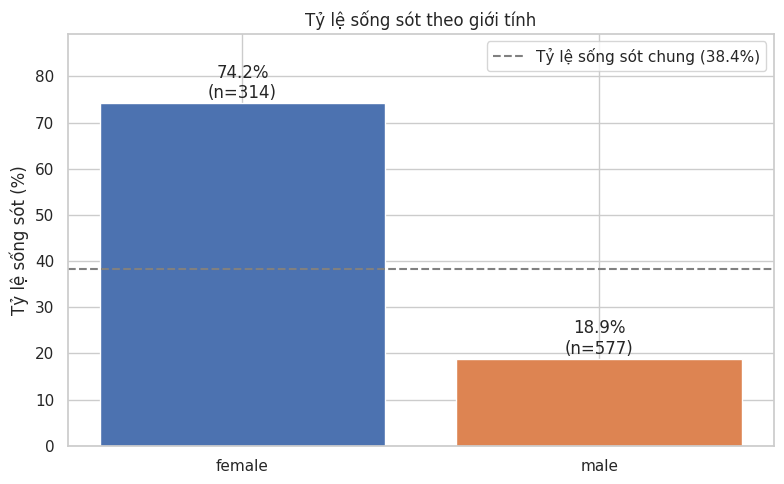

In [16]:
chi2_test('Sex')
g = rate_bar('Sex', title='Tỷ lệ sống sót theo giới tính', fname='05_survival_sex')

**Diễn giải:** Tỷ lệ sống sót của nữ khoảng **74,2%**, cao hơn đáng kể so với nam, khoảng **18,9%**. Kiểm định Chi-square cho p-value = 1,20 × 10⁻⁵⁸ và Cramér's V = 0,54, cho thấy mối liên hệ mạnh giữa giới tính và tình trạng sống sót trong mẫu. Kết quả ủng hộ H1. Tuy nhiên, đây là mối liên hệ quan sát được, không phải bằng chứng rằng giới tính là nguyên nhân duy nhất quyết định kết quả.

### H2 – Hạng vé (địa vị kinh tế)

[Pclass] Chi-square = 102.89, df = 2, p-value = 4.549e-23, Cramér's V = 0.340
Ô có tần suất kỳ vọng < 5: 0/6 (0.0%)
Kết luận: Có bằng chứng về mối liên hệ thống kê (p < 0,05).


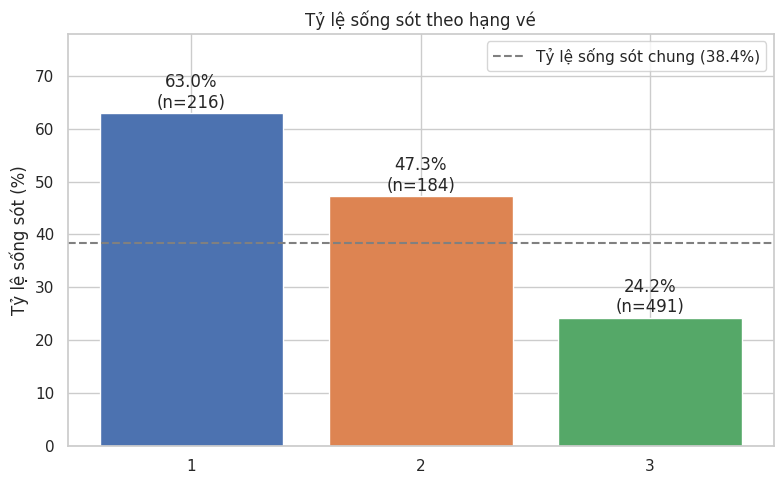

In [17]:
chi2_test('Pclass')
g = rate_bar('Pclass', order=[1, 2, 3], title='Tỷ lệ sống sót theo hạng vé', fname='06_survival_pclass')

**Diễn giải:** Tỷ lệ sống sót giảm theo hạng vé: hạng 1 khoảng **63,0%**, hạng 2 khoảng **47,3%** và hạng 3 khoảng **24,2%**. Kiểm định Chi-square cho p-value = 4,55 × 10⁻²³, Cramér's V = 0,34. Kết quả ủng hộ H2 và cho thấy hạng vé có mối liên hệ đáng kể với khả năng sống sót. Không nên diễn giải đây là tác động nhân quả độc lập vì hạng vé có thể liên quan đến vị trí, điều kiện tiếp cận và các đặc điểm khác của hành khách.

### H3 – Tuổi

[AgeGroup] Chi-square = 23.40, df = 4, p-value = 1.055e-04, Cramér's V = 0.162
Ô có tần suất kỳ vọng < 5: 0/10 (0.0%)
Kết luận: Có bằng chứng về mối liên hệ thống kê (p < 0,05).


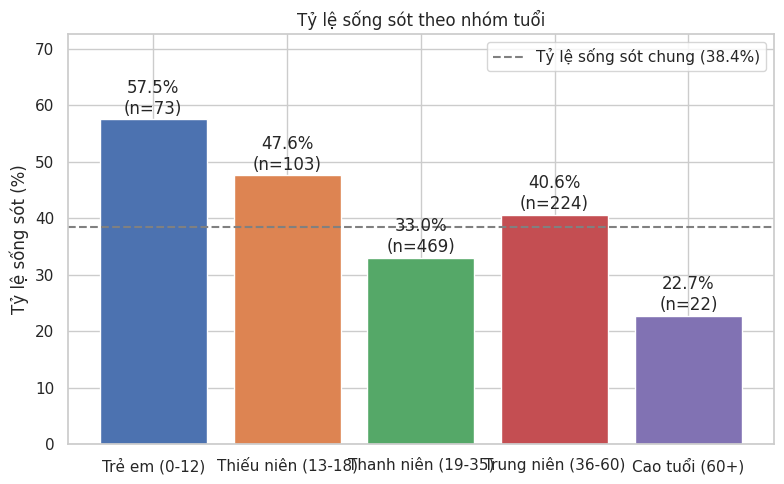

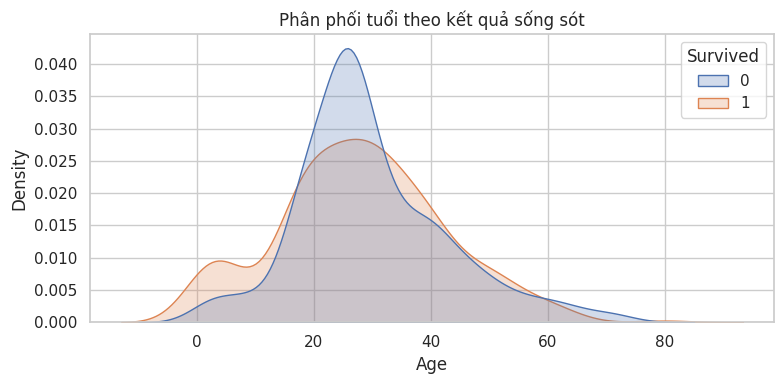

Mann-Whitney Age: U = 89260, p-value = 0.216
Median Age - sống sót: 27.5 | tử vong: 26.0


In [18]:
order = list(df['AgeGroup'].cat.categories)
chi2_test('AgeGroup')
g = rate_bar('AgeGroup', order=order, title='Tỷ lệ sống sót theo nhóm tuổi', fname='07_survival_agegroup')

# Phân phối tuổi theo kết quả sống sót + kiểm định Mann-Whitney
fig, ax = plt.subplots(figsize=(8, 4))
sns.kdeplot(data=df, x='Age', hue='Survived', fill=True, common_norm=False, ax=ax)
ax.set_title('Phân phối tuổi theo kết quả sống sót')
save_show('08_age_kde')
u, p = stats.mannwhitneyu(df.loc[df.Survived == 1, 'Age'], df.loc[df.Survived == 0, 'Age'])
print(f'Mann-Whitney Age: U = {u:.0f}, p-value = {p:.3f}')
print('Median Age - sống sót:', df.loc[df.Survived == 1, 'Age'].median(),
      '| tử vong:', df.loc[df.Survived == 0, 'Age'].median())

**Diễn giải:** Kiểm định Chi-square theo nhóm tuổi cho p-value = 1,05 × 10⁻⁴, Cramér's V = 0,16; đây là bằng chứng về mối liên hệ nhưng cỡ ảnh hưởng nhỏ. Trong khi đó, Mann–Whitney trên tuổi đã điền cho p-value = 0,216 và trung vị tuổi giữa hai nhóm không khác biệt lớn (27,5 so với 26 tuổi). Hai kiểm định trả lời hai câu hỏi khác nhau: kiểm định nhóm tuổi so sánh phân bố tỷ lệ sống sót giữa các khoảng tuổi, còn Mann–Whitney so sánh phân phối tuổi giữa hai nhóm kết quả. Vì vậy, cần tránh kết luận rằng tuổi nói chung là yếu tố mạnh; khác biệt có thể tập trung ở một số nhóm tuổi, đặc biệt là trẻ em.

**Kiểm tra độ nhạy (sensitivity check):** Các kết quả phân tích tuổi ở trên được tính trên biến `Age` đã xử lý giá trị khuyết thiếu. Để đánh giá mức độ phụ thuộc của kết luận vào phương pháp xử lý dữ liệu thiếu, phần dưới đây thực hiện lại hai kiểm định trên dữ liệu `Age` gốc, chỉ giữ lại các hành khách có tuổi được ghi nhận.

In [19]:
# Kiểm tra lại H3 trên dữ liệu Age GỐC (bỏ các dòng thiếu tuổi, không điền)
goc = train[['Age', 'Survived']].dropna()
print('Số hành khách có tuổi gốc:', len(goc))

# (a) Mann-Whitney trên tuổi gốc
u, p_mw = stats.mannwhitneyu(goc.loc[goc.Survived == 1, 'Age'], goc.loc[goc.Survived == 0, 'Age'])
print(f'Mann-Whitney (tuổi gốc): p-value = {p_mw:.3f}')

# (b) Chi-square theo nhóm tuổi trên tuổi gốc
goc['AgeGroup'] = pd.cut(goc['Age'], bins=[0, 12, 18, 35, 60, 100])
chi2_goc, p_chi, _, _ = stats.chi2_contingency(pd.crosstab(goc['AgeGroup'], goc['Survived']))
print(f'Chi-square nhóm tuổi (tuổi gốc): p-value = {p_chi:.2e}')
print('Tỷ lệ sống sót theo nhóm tuổi (tuổi gốc, %):')
print((goc.groupby('AgeGroup', observed=True)['Survived'].mean() * 100).round(1))

print('\nSo với dữ liệu đã điền: Mann-Whitney p = 0.216, Chi-square p = 1.05e-04')
print('Mann-Whitney:', 'tuổi KHÔNG phân biệt hai nhóm' if p_mw >= 0.05 else 'tuổi phân biệt được hai nhóm')
print('Chi-square  :', 'có liên hệ' if p_chi < 0.05 else 'không đủ bằng chứng')

Số hành khách có tuổi gốc: 714
Mann-Whitney (tuổi gốc): p-value = 0.160
Chi-square nhóm tuổi (tuổi gốc): p-value = 1.38e-02
Tỷ lệ sống sót theo nhóm tuổi (tuổi gốc, %):
AgeGroup
(0, 12]      58.0
(12, 18]     42.9
(18, 35]     38.3
(35, 60]     40.0
(60, 100]    22.7
Name: Survived, dtype: float64

So với dữ liệu đã điền: Mann-Whitney p = 0.216, Chi-square p = 1.05e-04
Mann-Whitney: tuổi KHÔNG phân biệt hai nhóm
Chi-square  : có liên hệ


**Kết quả kiểm tra độ nhạy:** Trong 891 hành khách, có 714 người có thông tin tuổi gốc. Trên tập quan sát này, kiểm định Mann–Whitney cho p-value = **0,160**, chưa đủ bằng chứng cho thấy phân phối tuổi khác biệt có ý nghĩa thống kê giữa hai nhóm sống sót và tử vong. Kiểm định Chi-square theo nhóm tuổi cho p-value = **0,0138**, cho thấy vẫn tồn tại mối liên hệ có ý nghĩa thống kê giữa nhóm tuổi và tình trạng sống sót.

So với dữ liệu đã điền khuyết (Mann–Whitney p = **0,216**; Chi-square p = **1,05 × 10⁻⁴**), kết luận ở mức ý nghĩa 5% không thay đổi: kiểm định Mann–Whitney không có ý nghĩa thống kê, còn kiểm định Chi-square có ý nghĩa thống kê. Tuy nhiên, p-value của Chi-square thay đổi, cho thấy mức độ bằng chứng có thể nhạy cảm với cách xử lý dữ liệu thiếu. Tỷ lệ sống sót ở nhóm 0–12 tuổi trên dữ liệu gốc là **58,0%**, cao hơn các nhóm tuổi trưởng thành trong phần lớn các khoảng tuổi.

### H4 – Quy mô gia đình

[FamilyGroup] Chi-square = 74.54, df = 2, p-value = 6.523e-17, Cramér's V = 0.289
Ô có tần suất kỳ vọng < 5: 0/6 (0.0%)
Kết luận: Có bằng chứng về mối liên hệ thống kê (p < 0,05).


,Ty_le_song_sot,So_hanh_khach
FamilyGroup,,
Đi một mình (1),30.4,537
Gia đình nhỏ/vừa (2–4),57.9,292
Gia đình đông (5+),16.1,62


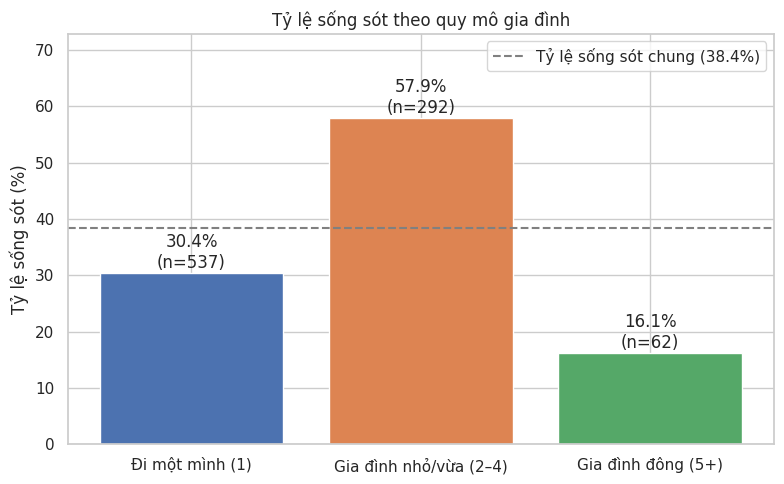

,mean,count
FamilyGroup,,
Đi một mình (1),0.303538,537
Gia đình nhỏ/vừa (2–4),0.578767,292
Gia đình đông (5+),0.161290,62


In [20]:
# Gộp quy mô gia đình thành các nhóm có ý nghĩa và hạn chế ô có tần suất quá nhỏ.
df['FamilyGroup'] = pd.cut(
    df['FamilySize'],
    bins=[0, 1, 4, np.inf],
    labels=['Đi một mình (1)', 'Gia đình nhỏ/vừa (2–4)', 'Gia đình đông (5+)']
)

family_test = chi2_test('FamilyGroup')
family_summary = (
    df.groupby('FamilyGroup', observed=True)['Survived']
      .agg(Ty_le_song_sot='mean', So_hanh_khach='count')
)
family_summary['Ty_le_song_sot'] = (family_summary['Ty_le_song_sot'] * 100).round(1)
display(family_summary)

# Biểu đồ tỷ lệ sống sót theo nhóm gia đình; cỡ mẫu được thể hiện ở nhãn.
rate_bar(
    'FamilyGroup',
    order=['Đi một mình (1)', 'Gia đình nhỏ/vừa (2–4)', 'Gia đình đông (5+)'],
    title='Tỷ lệ sống sót theo quy mô gia đình',
    fname='09_survival_familygroup'
)

**Diễn giải:** Sau khi gộp thành 3 nhóm, tỷ lệ sống sót là: đi một mình **30,4%** (n = 537), gia đình nhỏ/vừa 2-4 người **57,9%** (n = 292), gia đình đông 5+ người **16,1%** (n = 62). Kiểm định Chi-square cho Chi2 = 74,54, p ≈ 6,5×10⁻¹⁷, Cramér's V = 0,29, và mọi ô đều có tần suất kỳ vọng ≥ 5 (nhỏ nhất khoảng 24), nên kiểm định đủ điều kiện. Kết quả ủng hộ H4: gia đình nhỏ/vừa có tỷ lệ sống sót cao hơn rõ rệt. Khi chưa gộp (9 nhóm), Chi2 = 80,67 nhưng 5/18 ô có tần suất kỳ vọng dưới 5 nên kém tin cậy hơn. Nhóm gia đình đông chỉ có 62 người nên cần thận trọng; đây là mối liên hệ quan sát được, chưa chứng minh nguyên nhân.

### H5 – Giá vé

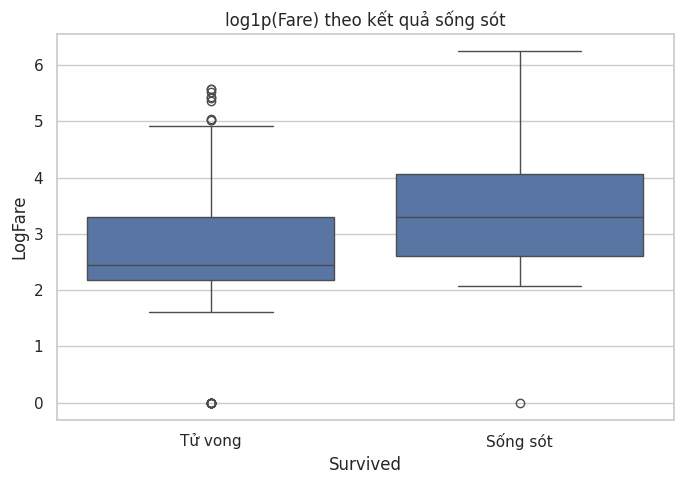

Mann-Whitney Fare: p-value = 4.55e-22
Median Fare - sống sót: 26.0 | tử vong: 10.5


In [21]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.boxplot(data=df, x='Survived', y='LogFare', ax=ax)
ax.set_xticklabels(['Tử vong', 'Sống sót']); ax.set_title('log1p(Fare) theo kết quả sống sót')
save_show('10_fare_survival')
u, p = stats.mannwhitneyu(df.loc[df.Survived == 1, 'Fare'], df.loc[df.Survived == 0, 'Fare'])
print(f'Mann-Whitney Fare: p-value = {p:.2e}')
print('Median Fare - sống sót:', df.loc[df.Survived == 1, 'Fare'].median(),
      '| tử vong:', df.loc[df.Survived == 0, 'Fare'].median())

**Diễn giải:** Giá vé trung vị của nhóm sống sót là **26,0**, cao hơn nhóm không sống sót (**10,5**); kiểm định Mann–Whitney cho p-value = 4,55 × 10⁻²². Kết quả cho thấy phân phối giá vé khác biệt có ý nghĩa thống kê giữa hai nhóm. Tuy nhiên, Fare có liên hệ chặt với Pclass nên không thể xem giá vé là yếu tố độc lập nếu chưa kiểm soát hạng vé và các biến khác.

### H6 – Cảng lên tàu và biến gây nhiễu

[Embarked] Chi-square = 25.96, df = 2, p-value = 2.301e-06, Cramér's V = 0.171
Ô có tần suất kỳ vọng < 5: 0/6 (0.0%)
Kết luận: Có bằng chứng về mối liên hệ thống kê (p < 0,05).


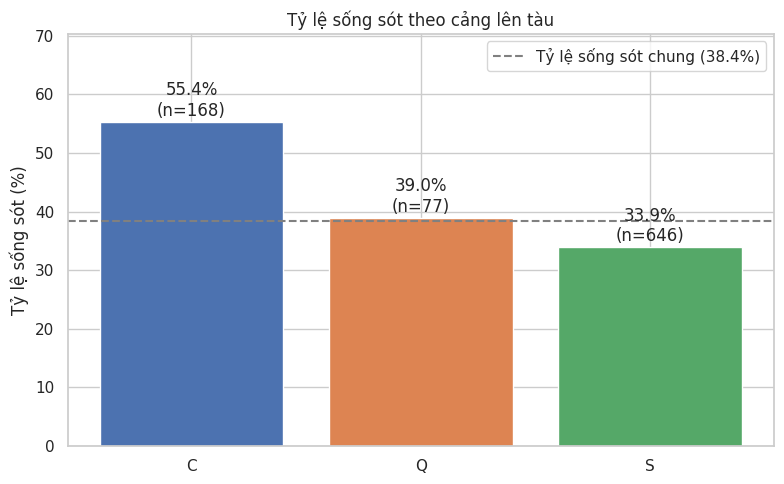

Cơ cấu hạng vé theo cảng (%):


Pclass,1,2,3
Embarked,,,
C,50.6,10.1,39.3
Q,2.6,3.9,93.5
S,20.0,25.4,54.6


In [22]:
chi2_test('Embarked')
g = rate_bar('Embarked', order=['C', 'Q', 'S'], title='Tỷ lệ sống sót theo cảng lên tàu', fname='11_survival_embarked')
print('Cơ cấu hạng vé theo cảng (%):')
display((pd.crosstab(df['Embarked'], df['Pclass'], normalize='index') * 100).round(1))

**Diễn giải:** Cảng C có tỷ lệ sống sót quan sát được cao nhất, nhưng cơ cấu hạng vé tại cảng này cũng khác: khoảng **50,6%** hành khách lên tàu tại C thuộc hạng 1, so với **20,0%** tại S và **2,6%** tại Q. Vì vậy, khác biệt tỷ lệ sống sót theo cảng có thể chịu ảnh hưởng của cơ cấu hạng vé và các yếu tố liên quan. Không nên kết luận bản thân cảng lên tàu làm tăng khả năng sống sót.

### Tương tác Giới tính × Hạng vé và ma trận tương quan

Tỷ lệ sống sót (%) theo giới tính và hạng vé:


Pclass,1,2,3
Sex,,,
female,96.8,92.1,50.0
male,36.9,15.7,13.5


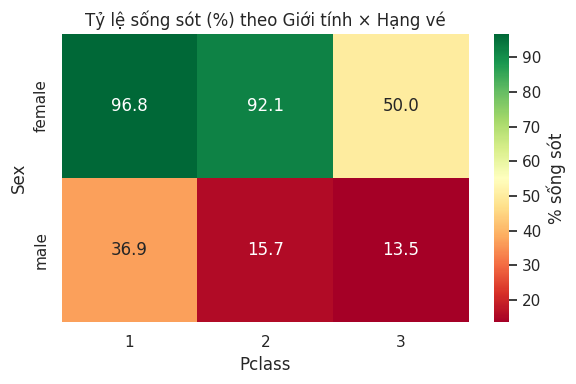

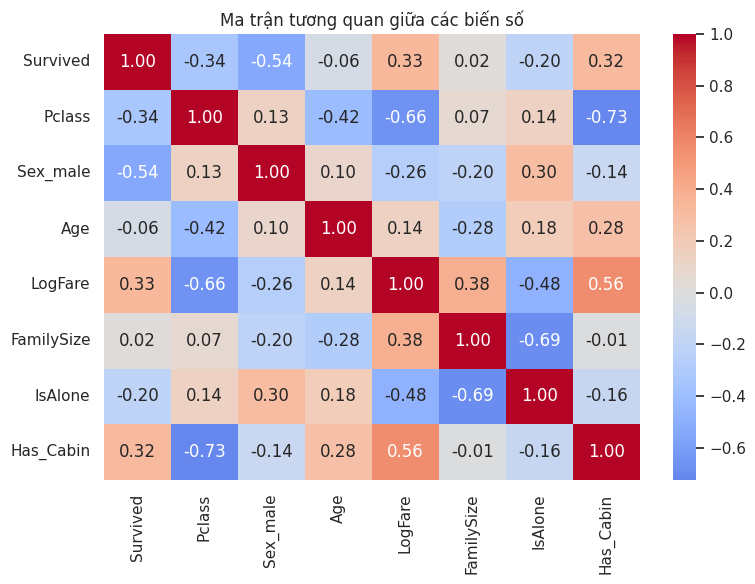

Tương quan với Survived (sắp xếp theo trị tuyệt đối):


,Correlation_with_Survived
Sex_male,-0.543351
Pclass,-0.338481
LogFare,0.329862
Has_Cabin,0.316912
IsAlone,-0.203367
Age,-0.062756
FamilySize,0.016639


In [23]:
# ============================================================
# 3.2. PHÂN TÍCH TƯƠNG TÁC VÀ TƯƠNG QUAN
# Heatmap thứ nhất: tỷ lệ sống sót theo kết hợp giới tính và hạng vé.
# Heatmap thứ hai: tương quan tuyến tính giữa các biến số đã mã hóa.
# ============================================================
survival_pivot = (
    df.pivot_table(
        index="Sex", columns="Pclass",
        values="Survived", aggfunc="mean"
    ) * 100
)
print("Tỷ lệ sống sót (%) theo giới tính và hạng vé:")
display(survival_pivot.round(1))

fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(
    survival_pivot, annot=True, fmt=".1f",
    cmap="RdYlGn", cbar_kws={"label": "% sống sót"}, ax=ax
)
ax.set_title("Tỷ lệ sống sót (%) theo Giới tính × Hạng vé")
save_show("12_heatmap_sex_pclass")

# Mã hóa giới tính thành biến nhị phân để có thể đưa vào ma trận tương quan.
df["Sex_male"] = (df["Sex"] == "male").astype(int)
corr_cols = [
    "Survived", "Pclass", "Sex_male", "Age", "LogFare",
    "FamilySize", "IsAlone", "Has_Cabin"
]
correlation_matrix = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    correlation_matrix, annot=True, fmt=".2f",
    cmap="coolwarm", center=0, ax=ax
)
ax.set_title("Ma trận tương quan giữa các biến số")
save_show("13_correlation")

print("Tương quan với Survived (sắp xếp theo trị tuyệt đối):")
display(
    correlation_matrix["Survived"]
    .drop("Survived")
    .to_frame("Correlation_with_Survived")
    .assign(Abs=lambda x: x["Correlation_with_Survived"].abs())
    .sort_values("Abs", ascending=False)
    .drop(columns="Abs")
)

**Diễn giải:** Heatmap giới tính × hạng vé cho phép quan sát đồng thời hai đặc điểm thay vì phân tích từng biến riêng lẻ. Khi đọc biểu đồ, cần so sánh các ô trong cùng một giới tính và giữa hai giới tính ở cùng hạng vé; đồng thời chú ý cỡ mẫu của từng nhóm nếu có bảng tần suất đi kèm. Nếu nhóm nữ có tỷ lệ sống sót cao hơn nhóm nam ở nhiều hạng vé, điều đó cho thấy khác biệt giới tính vẫn hiện diện khi phân tầng theo hạng vé, nhưng chưa thay thế được mô hình điều chỉnh nhiều biến.

Ma trận tương quan chỉ đo mức độ liên hệ tuyến tính giữa các biến số đã mã hóa. Dấu dương/âm thể hiện chiều đồng biến/nghịch biến, còn trị tuyệt đối càng lớn thể hiện liên hệ tuyến tính càng rõ trong mẫu. Các biến `Pclass`, `LogFare` và `Has_Cabin` có thể cùng phản ánh một phần điều kiện/hạng vé, do đó tương quan không nên được hiểu là tác động độc lập. Nhóm sử dụng hồi quy logistic nhiều biến ở phần tiếp theo để xem xét mối liên hệ có điều kiện.

## 3.2 Hồi quy logistic nhiều biến (kiểm soát đồng thời nhiều yếu tố)

Các kiểm định ở trên xem xét mối liên hệ giữa từng biến giải thích và tình trạng sống sót. Hồi quy logistic nhiều biến được sử dụng để xem xét mối liên hệ có điều kiện giữa từng đặc điểm và khả năng sống sót khi đồng thời đưa các yếu tố khác vào mô hình. Kết quả được trình bày dưới dạng **Odds Ratio (OR)**. OR lớn hơn 1 biểu thị odds sống sót cao hơn, OR nhỏ hơn 1 biểu thị odds thấp hơn so với nhóm tham chiếu, trong điều kiện các biến khác không đổi. OR không phải là mức thay đổi trực tiếp của xác suất sống sót.

In [24]:
# ============================================================
# 3.3. HỒI QUY LOGISTIC NHIỀU BIẾN
# Dùng GLM Binomial để ước lượng hệ số, Odds Ratio, CI 95% và p-value.
# Nhóm tham chiếu: nữ, Pclass 1, Embarked C.
# ============================================================
import statsmodels.api as sm

# Chọn biến giải thích; Pclass được mã hóa dạng phân loại.
or_data = df[
    ["Sex", "Age", "FamilySize", "LogFare", "Pclass", "Embarked"]
].copy()
or_data["Pclass"] = or_data["Pclass"].astype(str)

# One-Hot Encoding và bỏ nhóm đầu làm nhóm tham chiếu.
or_X = pd.get_dummies(
    or_data,
    columns=["Sex", "Pclass", "Embarked"],
    drop_first=True,
    dtype=float
)
or_X = sm.add_constant(or_X, has_constant="add")

# Ước lượng mô hình nhị phân; hệ số được chuyển sang Odds Ratio để diễn giải.
glm_model = sm.GLM(
    df["Survived"].astype(float),
    or_X.astype(float),
    family=sm.families.Binomial()
).fit()

conf_int = glm_model.conf_int()
or_table = pd.DataFrame({
    "Bien": glm_model.params.index,
    "Coefficient": glm_model.params.values,
    "Odds_Ratio": np.exp(glm_model.params.values),
    "CI95_lower": np.exp(conf_int[0].values),
    "CI95_upper": np.exp(conf_int[1].values),
    "p_value": glm_model.pvalues.values
})
or_table = or_table.loc[or_table["Bien"] != "const"].copy()
or_table[["Coefficient", "Odds_Ratio", "CI95_lower", "CI95_upper"]] = (
    or_table[["Coefficient", "Odds_Ratio", "CI95_lower", "CI95_upper"]].round(3)
)
or_table["p_value"] = or_table["p_value"].map(lambda value: f"{value:.3e}")
display(or_table.sort_values("Odds_Ratio"))

print(
    "Nhóm tham chiếu: nữ, hạng vé 1 và cảng C. "
    "OR < 1 biểu thị odds sống sót thấp hơn nhóm tham chiếu "
    "khi giữ các biến khác không đổi."
)

,Bien,Coefficient,Odds_Ratio,CI95_lower,CI95_upper,p_value
4,Sex_male,-2.697,0.067,0.045,0.100,1.357e-40
6,Pclass_3,-1.923,0.146,0.071,0.303,2.324e-07
5,Pclass_2,-0.781,0.458,0.241,0.871,1.725e-02
8,Embarked_S,-0.372,0.690,0.430,1.106,1.229e-01
2,FamilySize,-0.321,0.725,0.620,0.848,5.744e-05
7,Embarked_Q,-0.176,0.838,0.392,1.794,6.494e-01
1,Age,-0.044,0.957,0.942,0.973,8.919e-08
3,LogFare,0.374,1.454,1.045,2.023,2.648e-02


Nhóm tham chiếu: nữ, hạng vé 1 và cảng C. OR < 1 biểu thị odds sống sót thấp hơn nhóm tham chiếu khi giữ các biến khác không đổi.


**Diễn giải hồi quy đa biến:** Bảng kết quả trình bày hệ số hồi quy, Odds Ratio (OR), khoảng tin cậy 95% và p-value cho từng biến. Nhóm tham chiếu là nữ, hành khách hạng vé 1 và cảng C. Khi diễn giải, cần đọc OR cùng khoảng tin cậy: OR lớn hơn 1 biểu thị odds sống sót cao hơn nhóm tham chiếu; OR nhỏ hơn 1 biểu thị odds thấp hơn, trong điều kiện các biến còn lại không đổi. Nếu khoảng tin cậy 95% chứa 1 hoặc p-value không nhỏ hơn 0,05, chưa đủ bằng chứng thống kê để kết luận hệ số khác 0 ở mức ý nghĩa 5%.

Kết quả hồi quy là mối liên hệ có điều kiện theo các biến đã đưa vào mô hình, không phải xác suất sống sót trực tiếp và cũng không chứng minh quan hệ nhân quả. Đặc biệt, `Pclass` và `LogFare` có thể mang thông tin chồng lấn; vì vậy cần thận trọng khi diễn giải từng hệ số như một tác động hoàn toàn độc lập.

## 3.3 Mô hình dự báo cơ sở
Dùng Logistic Regression (dễ diễn giải) và Random Forest (bắt quan hệ phi tuyến) với 5-fold cross-validation phân tầng. Mục đích là **lượng hóa mức độ quan trọng của từng yếu tố**, không chỉ tối ưu độ chính xác.

Baseline Accuracy (luôn dự đoán lớp đa số): 0.616


,accuracy,precision,recall,roc_auc,f1
Logistic Regression,0.824 ± 0.011,0.785 ± 0.018,0.745 ± 0.032,0.876 ± 0.017,0.764 ± 0.018
Random Forest,0.834 ± 0.016,0.828 ± 0.026,0.716 ± 0.028,0.882 ± 0.022,0.768 ± 0.023


Classification report - Random Forest (out-of-fold):
              precision    recall  f1-score   support

     Tử vong      0.837     0.907     0.871       549
    Sống sót      0.828     0.716     0.768       342

    accuracy                          0.834       891
   macro avg      0.832     0.812     0.819       891
weighted avg      0.833     0.834     0.831       891



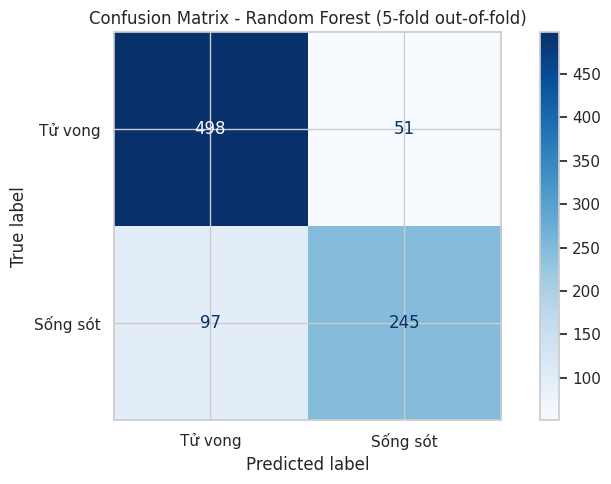

In [25]:
# ============================================================
# 3.4. XÂY DỰNG VÀ ĐÁNH GIÁ MÔ HÌNH DỰ BÁO
# So sánh Logistic Regression (dễ diễn giải) và Random Forest
# (có thể học quan hệ phi tuyến) bằng Stratified 5-fold CV.
# Mọi bước tiền xử lý được đặt trong Pipeline để hạn chế Data Leakage.
# ============================================================
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# Chia biến thành nhóm số và nhóm phân loại.
numeric_features = [
    "Age", "LogFare", "FamilySize", "Has_Cabin", "Age_missing"
]
categorical_features = ["Sex", "Embarked", "Title", "Pclass"]

# Biến số: điền Median và chuẩn hóa.
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Biến phân loại: điền mode và One-Hot Encoding.
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Kết hợp hai nhánh tiền xử lý.
prep = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

# Hai mô hình được đặt cùng quy trình tiền xử lý để so sánh công bằng.
models = {
    "Logistic Regression": Pipeline([
        ("prep", prep),
        ("clf", LogisticRegression(max_iter=2000, random_state=42))
    ]),
    "Random Forest": Pipeline([
        ("prep", prep),
        ("clf", RandomForestClassifier(
            n_estimators=400,
            min_samples_leaf=3,
            random_state=42,
            class_weight=None
        ))
    ])
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = {}

# Đánh giá bằng nhiều chỉ số, không chỉ Accuracy.
scoring_metrics = ["accuracy", "precision", "recall", "roc_auc", "f1"]
for model_name, model in models.items():
    scores = cross_validate(
        model, X_model, y, cv=cv,
        scoring=scoring_metrics,
        return_train_score=False
    )
    results[model_name] = {
        metric: (
            f"{scores[f'test_{metric}'].mean():.3f} ± "
            f"{scores[f'test_{metric}'].std():.3f}"
        )
        for metric in scoring_metrics
    }

baseline_accuracy = 1 - y.mean()
print(f"Baseline Accuracy (luôn dự đoán lớp đa số): {baseline_accuracy:.3f}")
cv_results = pd.DataFrame(results).T
display(cv_results)

# Dự đoán out-of-fold của Random Forest để lập Confusion Matrix.
# Mỗi hành khách được dự đoán bởi mô hình không được huấn luyện trên fold của họ.
rf_oof_pred = cross_val_predict(
    models["Random Forest"], X_model, y, cv=cv, method="predict"
)
print("Classification report - Random Forest (out-of-fold):")
print(classification_report(
    y, rf_oof_pred,
    target_names=["Tử vong", "Sống sót"],
    digits=3,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y, rf_oof_pred,
    display_labels=["Tử vong", "Sống sót"],
    cmap="Blues",
    values_format="d"
)
plt.title("Confusion Matrix - Random Forest (5-fold out-of-fold)")
save_show("15_confusion_matrix_rf")

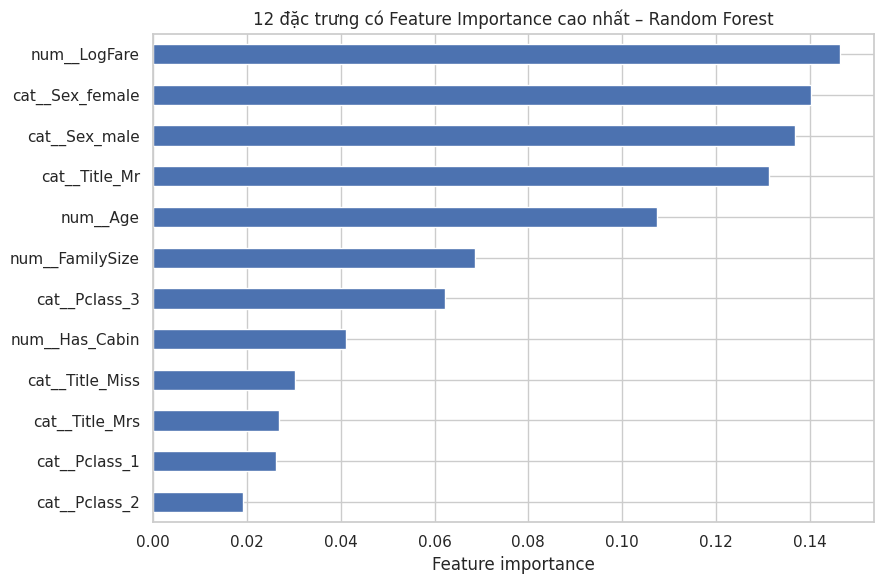

,0
num__LogFare,0.146
cat__Sex_female,0.140
cat__Sex_male,0.137
cat__Title_Mr,0.131
num__Age,0.107
num__FamilySize,0.069
cat__Pclass_3,0.062
num__Has_Cabin,0.041
cat__Title_Miss,0.030
cat__Title_Mrs,0.027


In [26]:
# ============================================================
# 3.5. PHÂN TÍCH FEATURE IMPORTANCE
# Fit mô hình trên toàn bộ train sau khi hoàn thành đánh giá CV.
# Feature importance chỉ phản ánh mức độ đóng góp dự báo trong mô hình.
# ============================================================
rf_model = models["Random Forest"].fit(X_model, y)

feature_names = rf_model.named_steps["prep"].get_feature_names_out()
importance = pd.Series(
    rf_model.named_steps["clf"].feature_importances_,
    index=feature_names
).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 6))
importance.head(12).sort_values().plot(kind="barh", ax=ax)
ax.set_title("12 đặc trưng có Feature Importance cao nhất – Random Forest")
ax.set_xlabel("Feature importance")
save_show("14_feature_importance")

display(importance.head(12).round(3))

**Diễn giải mô hình:** Kết quả kiểm định chéo phân tầng 5-fold được trình bày cho cả Logistic Regression và Random Forest theo năm chỉ số: Accuracy, Precision, Recall, ROC-AUC và F1-score. Baseline Accuracy là tỷ lệ của lớp chiếm đa số nếu mô hình luôn dự đoán hành khách không sống sót. Mô hình có giá trị sử dụng tốt hơn baseline cần thể hiện cải thiện không chỉ ở Accuracy mà còn ở các chỉ số phản ánh khả năng nhận diện nhóm sống sót.

Precision cho biết trong số các hành khách được mô hình dự đoán sống sót, tỷ lệ dự đoán đúng là bao nhiêu; Recall cho biết mô hình nhận diện được bao nhiêu phần trăm hành khách thực sự sống sót; F1-score cân bằng Precision và Recall. ROC-AUC đo khả năng phân biệt hai lớp trên nhiều ngưỡng dự đoán. Confusion Matrix và Classification Report được tính từ dự đoán out-of-fold, tức mỗi hành khách được dự đoán bởi mô hình không huấn luyện trên fold chứa hành khách đó.

Feature Importance của Random Forest được tính sau khi fit mô hình trên toàn bộ tập train. Đây là thước đo mức độ hữu ích tương đối của đặc trưng trong mô hình, không thể hiện chiều tác động và không chứng minh quan hệ nhân quả. Khi so sánh hai mô hình, nếu chênh lệch chỉ số nhỏ, nhóm nên ưu tiên mô hình dễ giải thích hoặc ổn định hơn thay vì khẳng định mô hình có điểm cao hơn một chút là vượt trội rõ rệt.

Sau đánh giá, Random Forest được fit trên toàn bộ train và áp dụng lên 418 quan sát trong `test.csv` để tạo `titanic_predictions.csv`. Vì test không có nhãn `Survived`, nhóm không tính Accuracy, Precision, Recall, F1-score hoặc ROC-AUC trên tập này.

In [27]:
# ============================================================
# 3.6. DỰ BÁO TRÊN TEST.CSV
# Tập test không có nhãn thật; chỉ tạo file kết quả theo định dạng Kaggle.
# ============================================================
if test is not None:
    X_test_model = build_model_features(test)
    test_predictions = rf_model.predict(X_test_model)

    submission = pd.DataFrame({
        "PassengerId": test["PassengerId"],
        "Survived": test_predictions.astype(int)
    })

    submission.to_csv("titanic_predictions.csv", index=False)
    print("Đã tạo titanic_predictions.csv với", len(submission), "dự đoán.")
    display(submission.head())
else:
    print("Không có test.csv; bỏ qua bước tạo file dự đoán.")

Đã tạo titanic_predictions.csv với 418 dự đoán.


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1


### Nhận xét và đánh giá giai đoạn 3

Phần phân tích đã kiểm tra sáu giả thuyết bằng các phương pháp phù hợp với dạng biến: Chi-square cho biến phân loại và Mann–Whitney U cho biến liên tục. Các biểu đồ cột thể hiện tỷ lệ sống sót theo nhóm kèm cỡ mẫu; boxplot và phân phối mật độ hỗ trợ so sánh biến liên tục; heatmap giúp quan sát tương tác giữa giới tính và hạng vé; ma trận tương quan tóm tắt liên hệ tuyến tính giữa các biến số.

Các kết quả nổi bật trong mẫu gồm: tỷ lệ sống sót của nữ cao hơn nam; tỷ lệ sống sót giảm theo hạng vé từ hạng 1 đến hạng 3; nhóm gia đình 2–4 người có tỷ lệ sống sót cao hơn nhóm đi một mình và nhóm gia đình đông; giá vé trung vị của nhóm sống sót cao hơn nhóm tử vong. Với tuổi, kiểm định Chi-square theo nhóm tuổi có ý nghĩa thống kê nhưng Mann–Whitney trên tuổi liên tục không có ý nghĩa ở mức 5%. Hai kiểm định trả lời hai câu hỏi khác nhau, do đó không nên gộp thành một kết luận đơn giản rằng tuổi có hoặc không có liên hệ.

Đối với cảng lên tàu, có sự khác biệt tỷ lệ sống sót giữa các cảng, nhưng cơ cấu hạng vé giữa các cảng cũng khác nhau. Vì vậy, chưa thể quy khác biệt này cho bản thân cảng lên tàu. Hồi quy logistic nhiều biến bổ sung góc nhìn có điều kiện khi đồng thời xem xét giới tính, tuổi, quy mô gia đình, giá vé, hạng vé và cảng lên tàu.

Hai mô hình dự báo được đánh giá bằng Stratified 5-fold Cross Validation. Việc báo cáo Accuracy, Precision, Recall, F1-score, ROC-AUC cùng Confusion Matrix giúp đánh giá cân bằng hơn trên dữ liệu có tỷ lệ hai lớp khác nhau. Dự đoán trên `test.csv` chỉ là kết quả áp dụng mô hình, không phải kết quả đánh giá vì không có nhãn thực tế.

**Kết luận giai đoạn 3:** dữ liệu cho thấy nhiều mối liên hệ thống kê đáng chú ý giữa đặc điểm hành khách và tình trạng sống sót. Tuy nhiên, đây là dữ liệu quan sát lịch sử; các kiểm định và mô hình dự báo không đủ cơ sở để khẳng định quan hệ nhân quả. Các nhận định phải được đặt trong phạm vi mẫu và giới hạn của dữ liệu.

# GIAI ĐOẠN 4: Đánh giá tác động và khuyến nghị

## 4.1. Các phát hiện chuyên môn nổi bật

1. **Giới tính có mối liên hệ mạnh với sống sót:** nữ có tỷ lệ sống sót khoảng **74,2%**, trong khi nam khoảng **18,9%**; Cramér's V = **0,541**. Đây là mối liên hệ mạnh nhất trong các phân tích đơn biến của nhóm.
2. **Hạng vé có liên hệ với sống sót:** tỷ lệ sống sót lần lượt khoảng **63,0%**, **47,3%** và **24,2%** ở hạng 1, 2 và 3; Cramér's V = **0,340**.
3. **Tuổi có kết quả phụ thuộc cách biểu diễn:** Chi-square theo nhóm tuổi có ý nghĩa thống kê, trong khi Mann–Whitney so sánh tuổi liên tục giữa hai nhóm không có ý nghĩa ở mức 5%. Trên 714 quan sát có tuổi gốc, Chi-square theo nhóm tuổi vẫn có ý nghĩa (p = **0,0138**), còn Mann–Whitney không có ý nghĩa (p = **0,160**).
4. **Quy mô gia đình có mối liên hệ:** nhóm gia đình 2–4 người có tỷ lệ sống sót **57,9%**, cao hơn nhóm đi một mình (**30,4%**) và gia đình đông từ 5 người (**16,1%**); p = **6,523 × 10⁻¹⁷**, Cramér's V = **0,289**.
5. **Giá vé khác biệt giữa hai nhóm kết quả:** trung vị Fare của nhóm sống sót là **26,0**, so với **10,5** ở nhóm tử vong; Mann–Whitney p = **4,55 × 10⁻²²**. Tuy nhiên, Fare có liên hệ với Pclass nên không nên diễn giải độc lập.
6. **Cảng lên tàu:** có mối liên hệ thống kê với tình trạng sống sót (p = **2,301 × 10⁻⁶**), nhưng cơ cấu hạng vé giữa các cảng khác nhau rõ rệt. Vì vậy, đây có thể là mối liên hệ chịu ảnh hưởng của biến khác.
7. **Mô hình dự báo:** kết quả so sánh Logistic Regression và Random Forest được trình bày trong bảng kiểm định chéo 5-fold cùng Precision, Recall, F1-score, ROC-AUC và Confusion Matrix. Nhóm sử dụng kết quả đó để lựa chọn mô hình phù hợp, không xem dự đoán trên test là độ chính xác đã được xác minh.

## 4.2. Đánh giá tác động và khuyến nghị

Các kết quả gợi ý rằng trong tình huống sơ tán khẩn cấp, khả năng tiếp cận thông tin, vị trí trên tàu, điều kiện di chuyển và cách tổ chức cứu hộ có thể liên quan đến kết quả sống sót. Từ góc độ quản lý an toàn hàng hải, nhóm đề xuất:

- **Thiết kế quy trình sơ tán dễ tiếp cận:** hướng dẫn thoát hiểm cần rõ ràng, dễ hiểu và được truyền đạt tới hành khách ở mọi khu vực, đặc biệt là những khu vực xa boong hoặc khó tiếp cận xuồng cứu sinh.
- **Bảo đảm hỗ trợ cho nhóm dễ gặp khó khăn khi di chuyển:** quy trình cần có phương án hỗ trợ trẻ em, người cao tuổi, người khuyết tật và người cần trợ giúp, thay vì chỉ dựa vào khả năng tự di chuyển.
- **Tổ chức cứu hộ theo nguyên tắc công bằng và an toàn:** kết quả lịch sử cho thấy khác biệt lớn giữa các nhóm hành khách; bài học ứng dụng là quy trình cứu hộ hiện đại cần dựa trên mức độ nguy cấp và nhu cầu hỗ trợ, không phân biệt theo giới tính, thu nhập hay hạng vé.
- **Cải thiện quản trị dữ liệu an toàn:** tàu cần lưu trữ thông tin hành khách, vị trí cabin và nhu cầu hỗ trợ ở mức cần thiết, cập nhật và bảo vệ phù hợp để hỗ trợ kiểm đếm, liên lạc và sơ tán khi xảy ra sự cố.
- **Sử dụng mô hình dự báo như công cụ nghiên cứu, không thay thế quyết định cứu hộ:** mô hình Titanic có thể minh họa cách phân tích dữ liệu lịch sử, nhưng không đủ điều kiện để tự động quyết định ưu tiên cứu người trong tình huống thực tế.

Các khuyến nghị trên là bài học định hướng từ phân tích dữ liệu lịch sử, không phải kết luận nhân quả được chứng minh bởi mô hình.

## 4.3. Hạn chế của nghiên cứu và hướng phát triển

**Hạn chế:**

1. **Quy mô và phạm vi dữ liệu:** tập train chỉ có 891 hành khách trên một chuyến tàu, do đó kết quả không đại diện cho mọi tai nạn hàng hải.
2. **Dữ liệu thiếu:** `Cabin` thiếu 77,10% và `Age` thiếu 19,87%; việc điền khuyết có thể ảnh hưởng đến phân phối và kết quả kiểm định.
3. **Thiếu biến quan trọng:** dữ liệu không mô tả đầy đủ vị trí thực tế của hành khách khi tai nạn xảy ra, khả năng tiếp cận xuồng cứu sinh, tình trạng sức khỏe, thời điểm sơ tán hoặc hành vi trong tình huống khẩn cấp.
4. **Nguy cơ biến gây nhiễu:** `Pclass`, `Fare`, `Cabin` và `Embarked` có thể liên quan với nhau. Hồi quy nhiều biến chỉ kiểm soát được các biến đã quan sát và đưa vào mô hình.
5. **Giới hạn suy luận:** dữ liệu mang tính quan sát, nên các mối liên hệ thống kê không chứng minh quan hệ nhân quả.
6. **Đánh giá mô hình:** kiểm định chéo được thực hiện trên train; tập test Kaggle không có nhãn thật nên không thể xác minh hiệu năng cuối cùng trên test. Kết quả còn phụ thuộc vào cách chia fold, lựa chọn đặc trưng và tham số mô hình.

**Hướng phát triển:**

- Bổ sung dữ liệu từ nhiều sự cố hàng hải để tăng tính đại diện.
- Thu thập thêm thông tin về vị trí cabin, khoảng cách tới xuồng cứu sinh, khả năng di chuyển và thời điểm sơ tán.
- So sánh thêm các mô hình như Gradient Boosting hoặc XGBoost (nếu môi trường cho phép), đồng thời điều chỉnh siêu tham số bằng quy trình cross-validation.
- Kiểm tra độ ổn định của mô hình trên các cách chia dữ liệu và tập dữ liệu độc lập.
- Sử dụng các phương pháp giải thích mô hình như permutation importance hoặc SHAP để đánh giá đóng góp của đặc trưng, đồng thời kiểm tra thiên lệch và tính công bằng.

**Kết luận giai đoạn 4:** nghiên cứu cung cấp một quy trình phân tích dữ liệu hoàn chỉnh từ đánh giá chất lượng, làm sạch, kiểm định giả thuyết đến xây dựng mô hình dự báo. Giá trị chính của bài tập là minh họa cách khai thác dữ liệu để rút ra nhận định có căn cứ, đồng thời nhận diện rõ giới hạn trước khi chuyển kết quả phân tích thành khuyến nghị thực tế.

## Nguồn dữ liệu, khả năng tái lập và tài liệu kèm theo

Dữ liệu được lấy từ cuộc thi **Titanic: Machine Learning from Disaster** trên Kaggle:  
https://www.kaggle.com/competitions/titanic/data

Notebook sử dụng hai tệp dữ liệu chính:
- `train.csv`: dữ liệu có nhãn `Survived`, dùng cho phân tích và huấn luyện/đánh giá mô hình.
- `test.csv`: dữ liệu không có nhãn `Survived`, dùng để tạo dự báo minh họa.

Notebook được thiết kế để chạy từ đầu đến cuối trên Google Colab sau khi người dùng tải lên đủ hai tệp CSV từ Kaggle. Các biểu đồ được lưu trong thư mục `figures/`; file dự báo được lưu dưới tên `titanic_predictions.csv`.

Thư viện chính gồm Python, pandas, NumPy, Matplotlib, Seaborn, SciPy, scikit-learn và statsmodels. Kết quả đánh giá mô hình được tính bằng Stratified 5-fold Cross Validation trên train. Do `test.csv` không có nhãn thực tế, không sử dụng tập này để báo cáo chỉ số đánh giá mô hình.

Khi hoàn thiện bài nộp, nhóm cần bổ sung đường dẫn GitHub Public chứa Notebook và báo cáo PDF vào phần tài liệu tham khảo hoặc trang bìa của báo cáo.